# 01 — Exploration de MovieLens 100K

Première prise en main du jeu de données : volumes, distribution des notes, genres, films les mieux notés et activité des utilisateurs. Données : GroupLens Research (voir le README pour les conditions d'utilisation).

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.data import download, load_ratings, load_movies, GENRES
download()
VIOLET, GOLD = "#8B5CF6", "#F5C451"


In [2]:
ratings = load_ratings()
movies = load_movies()
print(f"{len(ratings):,} notes · {ratings.user_id.nunique()} utilisateurs · {ratings.item_id.nunique()} films")
print('Valeurs manquantes :', int(ratings.isna().sum().sum()))
print('Doublons utilisateur–film :', int(ratings.duplicated(['user_id', 'item_id']).sum()))
densite = len(ratings) / (ratings.user_id.nunique() * ratings.item_id.nunique())
print(f'Densité de la matrice : {densite:.2%}')
ratings.head()

100,000 notes · 943 utilisateurs · 1682 films
Valeurs manquantes : 0
Doublons utilisateur–film : 0
Densité de la matrice : 6.30%


,user_id,item_id,rating,timestamp
0,196,242,3,881250949
1,186,302,3,891717742
2,22,377,1,878887116
3,244,51,2,880606923
4,166,346,1,886397596


## Distribution des notes

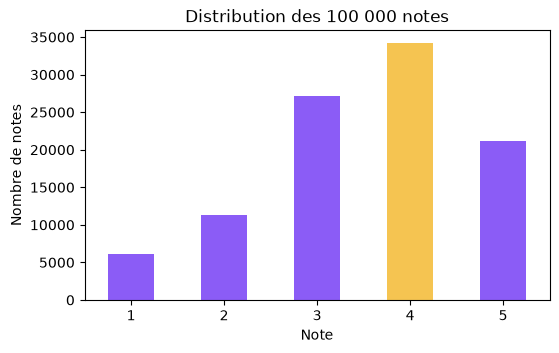

,%,notes
rating,,
1,6.11,6110
2,11.37,11370
3,27.15,27145
4,34.17,34174
5,21.20,21201


In [3]:
dist = ratings.rating.value_counts().sort_index()
ax = dist.plot.bar(color=[VIOLET, VIOLET, VIOLET, GOLD, VIOLET], rot=0, figsize=(6, 3.5))
ax.set_xlabel('Note'); ax.set_ylabel('Nombre de notes'); ax.set_title('Distribution des 100 000 notes')
plt.show()
(dist / len(ratings) * 100).round(2).rename('%').to_frame().assign(notes=dist)

## Notes par genre

Un film peut appartenir à plusieurs genres : chaque note est alors comptée dans chacun de ses genres (le total dépasse donc 100 000).

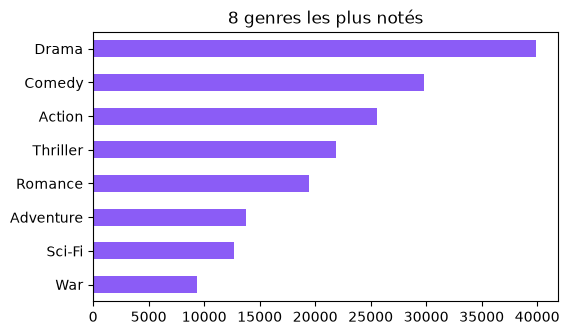

Drama        39895
Comedy       29832
Action       25589
Thriller     21872
Romance      19461
Adventure    13753
Sci-Fi       12730
War           9398
dtype: int64

In [4]:
data = ratings.merge(movies, on='item_id')
genres = pd.Series({g: int(data[g].sum()) for g in GENRES}).sort_values(ascending=False)
genres.head(8).sort_values().plot.barh(color=VIOLET, figsize=(6, 3.5), title='8 genres les plus notés')
plt.show()
genres.head(8)

## Films les mieux notés (au moins 100 notes)

Sans seuil, un film noté une seule fois 5/5 arriverait en tête : le seuil rend la moyenne plus fiable.

In [5]:
stats = data.groupby(['item_id', 'title']).rating.agg(moyenne='mean', notes='count').reset_index()
eligibles = stats[stats.notes >= 100]
print(f'{len(eligibles)} films ont au moins 100 notes')
eligibles.sort_values(['moyenne', 'notes'], ascending=False).head(5).round(3)

338 films ont au moins 100 notes


,item_id,title,moyenne,notes
407,408,"Close Shave, A (1995)",4.491,112
317,318,Schindler's List (1993),4.466,298
168,169,"Wrong Trousers, The (1993)",4.466,118
482,483,Casablanca (1942),4.457,243
63,64,"Shawshank Redemption, The (1994)",4.445,283


## Activité des utilisateurs

Chaque utilisateur a noté au moins 20 films, mais l'activité est très inégale : une longue traîne que les modèles doivent gérer.

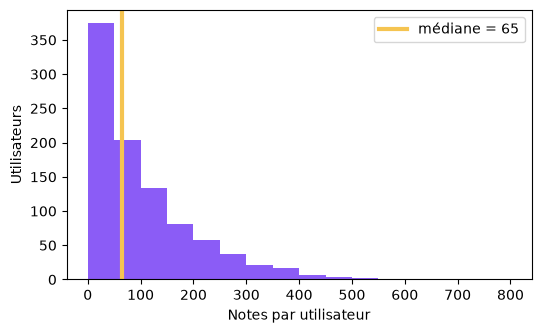

count    943.0
mean     106.0
std      100.9
min       20.0
25%       33.0
50%       65.0
75%      148.0
max      737.0
dtype: float64

In [6]:
par_user = ratings.groupby('user_id').size()
ax = par_user.plot.hist(bins=range(0, 801, 50), color=VIOLET, figsize=(6, 3.5))
ax.axvline(par_user.median(), color=GOLD, lw=3, label=f'médiane = {par_user.median():.0f}')
ax.set_xlabel('Notes par utilisateur'); ax.set_ylabel('Utilisateurs'); ax.legend()
plt.show()
par_user.describe().round(1)

## À retenir

- Matrice très creuse (~6 % de cases remplies) : c'est exactement le problème que la recommandation cherche à combler.
- Les notes sont plutôt positives (4 est la plus fréquente) : on considérera un film comme « pertinent » à partir de 4.
- Popularité et activité suivent une longue traîne : une référence par popularité sera difficile à battre en top-N.